# Analyze nested optimization histories

Load a `nested` optimization history (`*_nested_optimization_history_*.hdf5`) into a DataFrame and plot how the
parameters (and objectives) evolve over generations.

The DataFrame has two-level columns: `meta` (generation, model_id, survivor, energy, rank, fitness),
`param`, `feature` and `objective`. So `df['param']` is the param matrix and `df['feature', 'phase4_accuracy']` one feature.

In [65]:
import os
import glob

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

from nested.optimize_utils import OptimizationHistory, OptimizationReport

%matplotlib inline

## Choose a history file

In [66]:
history_dir = '../data/optimization_histories'

history_files = sorted(glob.glob(os.path.join(history_dir, '*nested_optimization_history*.hdf5')))
for i, path in enumerate(history_files):
    print(i, os.path.basename(path))

0 20261005_105117_nested_optimization_history_PopulationAnnealing_EIANN_2_hidden_CL_mnist_5_tasks_bpDale_relu_SGD_SI_A_124562835820294074569634942619043933184.hdf5
1 20261021_090019_nested_optimization_history_PopulationAnnealing_EIANN_2_hidden_CL_mnist_5_tasks_BTSP_SI_layer_lambda_6L_174809061727445107404272820349958289662.hdf5
2 20261022_112317_nested_optimization_history_PopulationAnnealing_EIANN_2_hidden_CL_mnist_5_tasks_bpDale_relu_SGD_SI_HD_v1_A_222310840085585834672606772235920912192.hdf5
3 20261027_144701_nested_optimization_history_PopulationAnnealing_EIANN_2_hidden_CL_mnist_5_tasks_BTSP_SI_layer_lambda_6L_320568214881298469769832423558211612976.hdf5
4 20261027_154153_nested_optimization_history_PopulationAnnealing_EIANN_2_hidden_CL_mnist_5_tasks_bpDale_relu_SGD_SI_HD_v1_A_206107264886958023403157002503359472584.hdf5


In [67]:
history_file_path = history_files[0]

# Optional: the optimize config the run used, to get param bounds (else bounds come from the observed range).
optimize_config_file_path = None  # e.g. '../optimize/optimize_config/mnist_CL/5_tasks/<config>.yaml'

## Load

In [68]:
def history_to_df(history, group='population'):
    '''
    Flatten an OptimizationHistory into one row per model.
    :param history: OptimizationHistory
    :param group: str; 'population', 'survivors', 'specialists', 'prev_survivors' or 'prev_specialists'
    :return: pd.DataFrame with column levels (category, name)
    '''
    populations = getattr(history, 'generations' if group == 'population' else group)
    rows = []
    for gen, population in enumerate(populations):
        for indiv in population:
            row = {('meta', 'generation'): gen, ('meta', 'model_id'): indiv.model_id,
                   ('meta', 'survivor'): bool(indiv.survivor), ('meta', 'energy'): indiv.energy,
                   ('meta', 'rank'): indiv.rank, ('meta', 'fitness'): indiv.fitness}
            row.update({('param', name): val for name, val in zip(history.param_names, indiv.x)})
            for category, names, vals in [('feature', history.feature_names, indiv.features),
                                          ('objective', history.objective_names, indiv.objectives)]:
                if vals is not None:
                    row.update({(category, name): val for name, val in zip(names, vals)})
            rows.append(row)
    if not rows:  # e.g. no failed models
        columns = [('meta', name) for name in ['generation', 'model_id', 'survivor', 'energy', 'rank', 'fitness']]
        return pd.DataFrame(columns=pd.MultiIndex.from_tuples(columns + [('param', n) for n in history.param_names]))
    df = pd.DataFrame(rows)
    df.columns = pd.MultiIndex.from_tuples(df.columns)
    return df


history = OptimizationHistory(file_path=history_file_path)
df = history_to_df(history)
survivors_df = history_to_df(history, 'survivors')
failed_df = history_to_df(history, 'failed')  # params only: nested stores no features for failed models
param_names = list(history.param_names)

print(f'{len(history.generations)} generations, {len(df)} models, {len(failed_df)} failed, '
      f'{len(param_names)} params, path_length={history.path_length}')
df.head()

OptimizationHistory: loading 150 generations from file: ../data/optimization_histories/20261005_105117_nested_optimization_history_PopulationAnnealing_EIANN_2_hidden_CL_mnist_5_tasks_bpDale_relu_SGD_SI_A_124562835820294074569634942619043933184.hdf5 took 12.04 s
150 generations, 24293 models, 5707 failed, 20 params, path_length=3


meta                                                        param  \
  generation model_id survivor    energy rank fitness H_E_E_learning_rate   
0          0        0     True  0.330354    0       0            0.476732   
1          0        1    False  5.448166  494     146            0.014374   
2          0        2     True  5.165687   21       0            0.024759   
3          0        3    False  5.672808  511     155            0.104421   
4          0        4     True  3.330072    6       0            0.056023   

                                                                     ...  \
  Output_E_E_learning_rate si_lambda H1_E_Input_E_init_weight_scale  ...   
0                 0.079524  0.100000                       3.058272  ...   
1                 0.002449  0.017274                       3.302420  ...   
2                 0.026282  6.848319                       0.485553  ...   
3                 0.023711  0.038990                       0.041420  ...   
4                 0.005178  0.014403                       0.045197  ...   

    objective                                                        \
  phase1_loss phase2_accuracy phase2_dynamics_residuals phase2_loss   
0    0.048514       63.669846                  0.246542    0.082616   
1    0.100000       83.408676                  1.878948    0.100000   
2    0.093504       83.060440                  1.513543    0.093573   
3    0.100000       83.408676                  2.373982    0.100000   
4    0.086089       81.669174                  0.108845    0.108975   

                                                                         \
  phase3_accuracy phase3_dynamics_residuals phase3_loss phase4_accuracy   
0       69.625656                  0.069466    0.093847       72.043602   
1       87.658783                  1.881190    0.100000       90.089996   
2       87.434372                  1.513531    0.093667       89.952797   
3       87.658783                  2.191778    0.100000       90.089996   
4       86.376587                  0.157257    0.116278       90.002197   

                                         
  phase4_dynamics_residuals phase4_loss  
0                  0.121626    0.102520  
1                  1.880274    0.100000  
2                  1.513281    0.093638  
3                  2.271503    0.100000  
4                  0.191925    0.110255  

[5 rows x 58 columns]

## Best model

In [69]:
report = OptimizationReport(history=history)
report.report_best()

params:
H_E_E_learning_rate: 0.09676683256327873
Output_E_E_learning_rate: 0.0002251150144171939
si_lambda: 1.1188173157795993
H1_E_Input_E_init_weight_scale: 1.5223309029046352
H1_E_H1_I_init_weight_scale: 1.232717562436333
H1_I_Input_E_init_weight_scale: 1.8251960608201365
H1_I_H1_E_init_weight_scale: 0.4821468939067459
H1_I_H1_I_init_weight_scale: 1.0967593888990148
H2_E_H1_E_init_weight_scale: 0.11346701332905754
H2_E_H2_I_init_weight_scale: 0.10319046233944146
H2_I_H1_E_init_weight_scale: 0.05306985115306578
H2_I_H2_E_init_weight_scale: 1.4255955160106
H2_I_H2_I_init_weight_scale: 1.3371419916617346
Output_E_H2_E_init_weight_scale: 3.480236607860408
Output_E_Output_I_init_weight_scale: 0.30242136219889637
Output_I_H2_E_init_weight_scale: 1.5256625008750753
Output_I_Output_E_init_weight_scale: 1.6491781653366402
Output_I_Output_I_init_weight_scale: 5.80335004131969
H_I_size: 50.0
Output_I_size: 10.0
features:
final_dynamics_residuals: 0.0
phase0_accuracy: 99.81898498535156
phase0_d

## Param bounds

From the optimize config if one is given, else the observed min/max. Params whose bounds span more than an order of
magnitude are plotted on a log axis (nested also steps these in log space).

In [70]:
def get_param_bounds(param_names, df, optimize_config_file_path=None):
    bounds = {}
    if optimize_config_file_path is not None:
        with open(optimize_config_file_path) as f:
            config_bounds = yaml.safe_load(f)['bounds']
        missing = [name for name in param_names if name not in config_bounds]
        if missing:
            print(f'Not in optimize config, using observed range: {missing}')
        bounds = {name: tuple(float(v) for v in config_bounds[name]) for name in param_names if name in config_bounds}
    for name in param_names:
        if name not in bounds:
            bounds[name] = (df['param', name].min(), df['param', name].max())
    return bounds


def use_log_scale(bound):
    lo, hi = bound
    return lo > 0 and hi / lo > 10


bounds = get_param_bounds(param_names, pd.concat([df, failed_df]), optimize_config_file_path)

/var/folders/b_/g86mqb050xqcjd0hx6_l6j780000gn/T/ipykernel_10730/3396778598.py:21: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  bounds = get_param_bounds(param_names, pd.concat([df, failed_df]), optimize_config_file_path)


## Top models

`nested`'s best model (above) is ranked over all objectives together. Here models are ranked by a single column
instead, which also sets the color in the plots below.

In [71]:
color_by = ('feature', 'phase4_accuracy')  # or ('objective', <name>), ('meta', 'energy')
higher_is_better = True  # True for accuracy features; False for objectives and energy
if color_by not in df.columns:
    color_by, higher_is_better = ('meta', 'energy'), False

top_n = 10
top = df.sort_values(color_by, ascending=not higher_is_better).head(top_n)
top[['meta', 'feature']]

meta                                           \
      generation model_id survivor    energy rank fitness   
23090        143    28746     True  0.646119   61       0   
23608        146    29284    False  0.580665   47       0   
23762        147    29448    False  0.624243   76       0   
22269        139    27870     True  0.561214   30       0   
22921        142    28568    False  0.612432   54       0   
23750        147    29436    False  0.615099   74       0   
23040        143    28692    False  0.587120   46       0   
22720        141    28350     True  0.531189    9       0   
24190        149    29891     True  0.515380    5       0   
22759        141    28390     True  0.568278   31       0   

                       feature                                            \
      final_dynamics_residuals phase0_accuracy phase0_dynamics_residuals   
23090                      0.0       99.826767                       0.0   
23608                      0.0       99.828705                       0.0   
23762                      0.0       99.820923                       0.0   
22269                      0.0       99.825790                       0.0   
22921                      0.0       99.819954                       0.0   
23750                      0.0       99.823853                       0.0   
23040                      0.0       99.819962                       0.0   
22720                      0.0       99.820923                       0.0   
24190                      0.0       99.821899                       0.0   
22759                      0.0       99.822876                       0.0   

                   ...                                                        \
      phase0_loss  ... phase1_loss phase2_accuracy phase2_dynamics_residuals   
23090    0.046462  ...    0.063646       71.311569                       0.0   
23608    0.044270  ...    0.061850       73.929016                       0.0   
23762    0.046439  ...    0.063982       73.713715                       0.0   
22269    0.044715  ...    0.063070       73.761932                       0.0   
22921    0.044303  ...    0.062153       73.527870                       0.0   
23750    0.042869  ...    0.060800       73.751213                       0.0   
23040    0.046540  ...    0.063223       75.586472                       0.0   
22720    0.042122  ...    0.061463       77.919640                       0.0   
24190    0.039499  ...    0.059235       78.270218                       0.0   
22759    0.041377  ...    0.059930       75.771973                       0.0   

                                                                         \
      phase2_loss phase3_accuracy phase3_dynamics_residuals phase3_loss   
23090    0.076177       69.793518                       0.0    0.081953   
23608    0.074797       71.601486                       0.0    0.080814   
23762    0.076819       70.116562                       0.0    0.082840   
22269    0.075698       73.151688                       0.0    0.081502   
22921    0.074793       71.046326                       0.0    0.080784   
23750    0.073603       70.185066                       0.0    0.079782   
23040    0.075784       71.306351                       0.0    0.081524   
22720    0.074812       72.731018                       0.0    0.081539   
24190    0.072357       72.834122                       0.0    0.079105   
22759    0.072880       71.594284                       0.0    0.079235   

                                                             
      phase4_accuracy phase4_dynamics_residuals phase4_loss  
23090       67.471207                       0.0    0.084992  
23608       67.096199                       0.0    0.083628  
23762       66.947800                       0.0    0.085620  
22269       66.446404                       0.0    0.083393  
22921       66.427200                       0.0    0.084112  
23750       66.326004                       0.0    0.082515  
23040   

## Objectives over generations

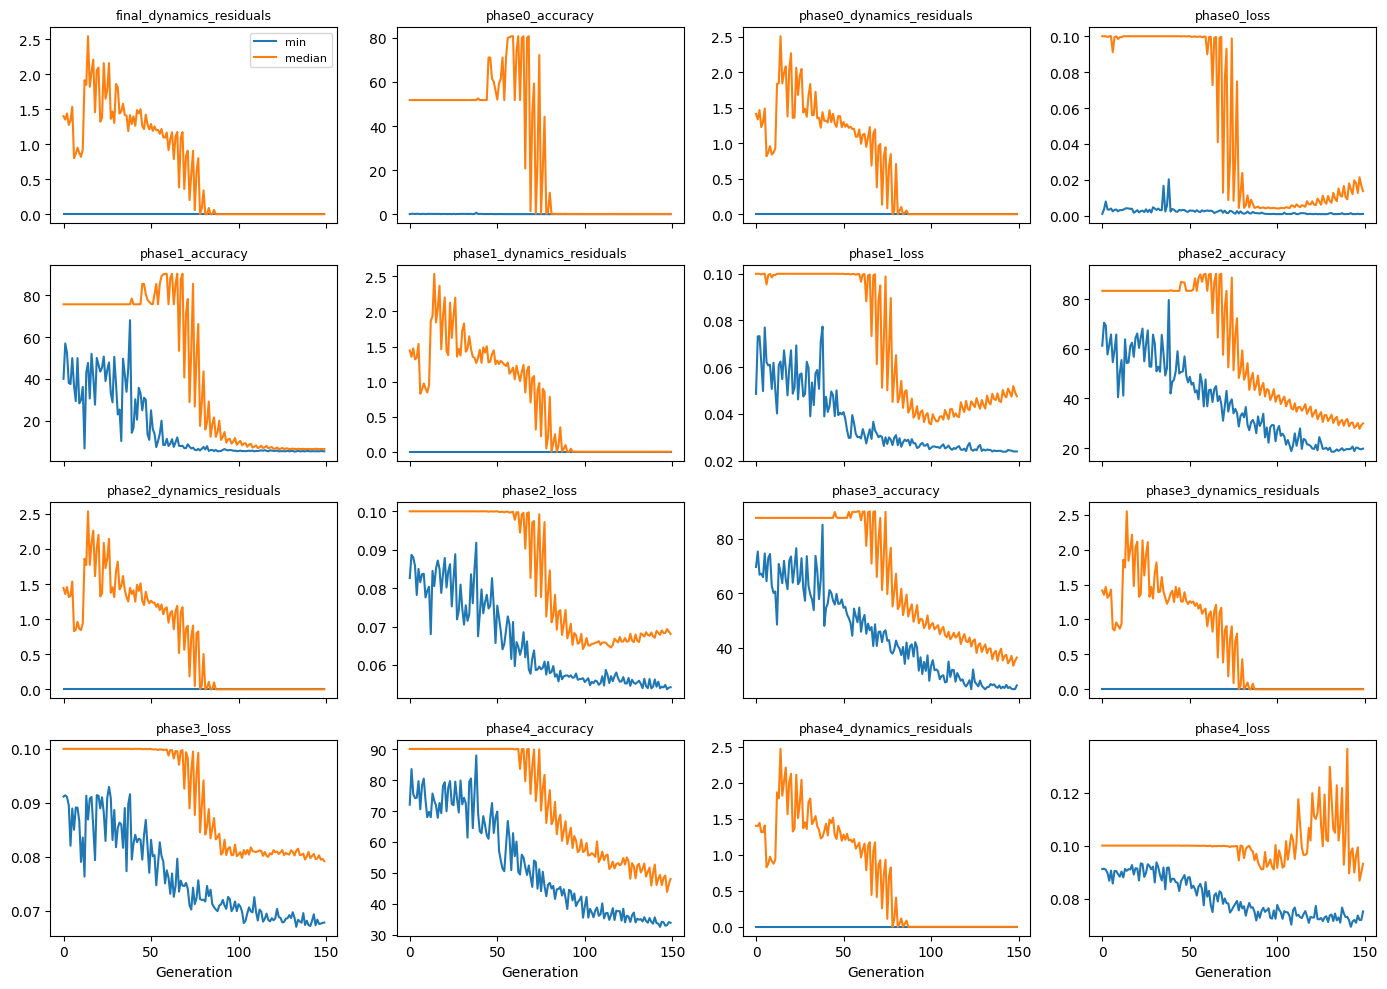

In [72]:
objective_names = list(history.objective_names)

ncols = 4
nrows = int(np.ceil(len(objective_names) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.5 * ncols, 2.5 * nrows), sharex=True, squeeze=False)
for ax, name in zip(axes.flat, objective_names):
    by_gen = df['objective', name].groupby(df['meta', 'generation'])
    ax.plot(by_gen.min(), label='min')
    ax.plot(by_gen.median(), label='median')
    ax.set_title(name, fontsize=9)
for ax in axes.flat[len(objective_names):]:
    ax.axis('off')
for ax in axes[-1]:
    ax.set_xlabel('Generation')
axes.flat[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## Param values over generations

Every model is a dot, colored by `color_by` (a feature or objective name, or `energy`). The line is the best survivor
of each generation, as ranked by nested over all objectives. Gray x = failed models, drawn underneath (turn off with `show_failed`).

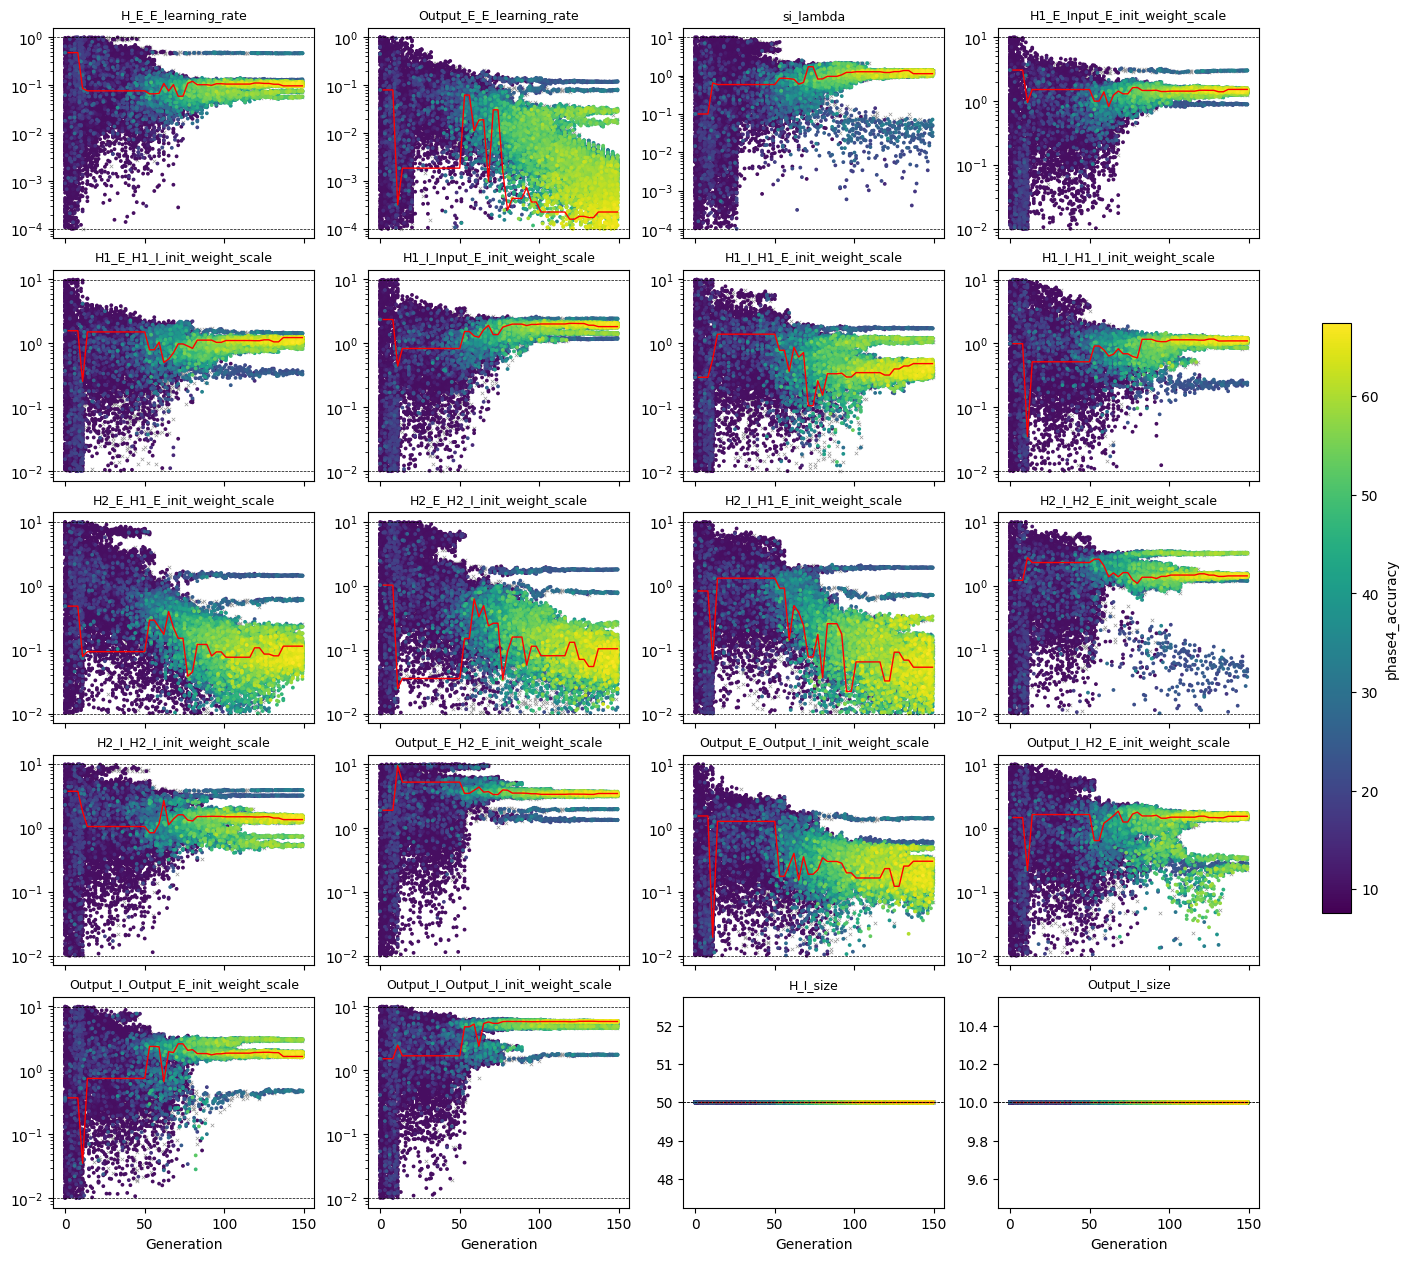

In [73]:
show_failed = True

# draw the best models last so they sit on top
df_plot = df.sort_values(color_by, ascending=not higher_is_better).iloc[::-1]
best_per_gen = survivors_df.groupby(survivors_df['meta', 'generation']).first()  # nested's best survivor per generation

ncols = 4
nrows = int(np.ceil(len(param_names) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.5 * ncols, 2.5 * nrows), sharex=True, squeeze=False,
                         constrained_layout=True)
for ax, name in zip(axes.flat, param_names):
    sc = ax.scatter(df_plot['meta', 'generation'], df_plot['param', name], c=df_plot[color_by], s=3,
                    cmap='viridis' if higher_is_better else 'viridis_r', rasterized=True)
    if show_failed:
        ax.scatter(failed_df['meta', 'generation'], failed_df['param', name], c='0.6', marker='x', s=6, lw=0.5,
                   zorder=0, rasterized=True)
    ax.plot(best_per_gen.index, best_per_gen['param', name], c='r', lw=1)
    for b in bounds[name]:
        ax.axhline(b, c='k', ls='--', lw=0.5)
    if use_log_scale(bounds[name]):
        ax.set_yscale('log')
    ax.set_title(name, fontsize=9)
for ax in axes.flat[len(param_names):]:
    ax.axis('off')
for ax in axes[-1]:
    ax.set_xlabel('Generation')
fig.colorbar(sc, ax=axes, label=color_by[1], shrink=0.5)
plt.show()

## Final survivors within bounds

Each survivor's params normalized to [0, 1] within the bounds (log-normalized for log-scale params). Params piled up at
0 or 1 are pinned at a bound, which suggests widening it.

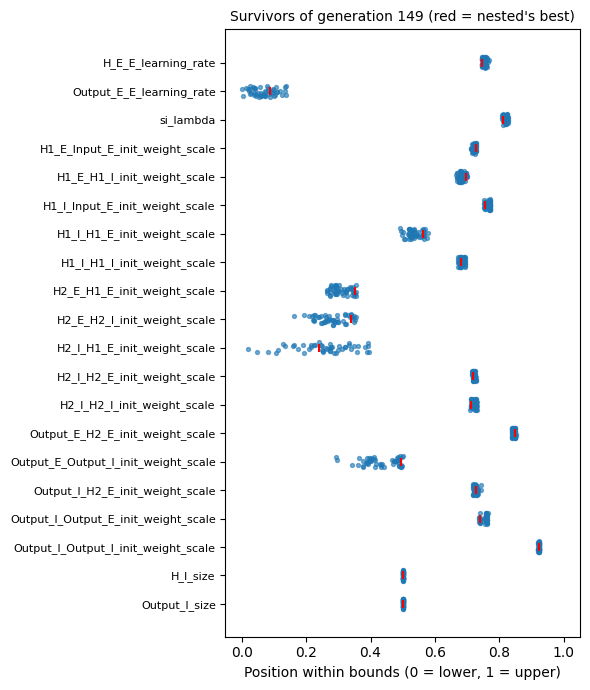

In [74]:
last_gen = survivors_df['meta', 'generation'].max()
final = survivors_df[survivors_df['meta', 'generation'] == last_gen]

def normalize(vals, bound):
    lo, hi = bound
    if hi == lo:
        return np.full(len(vals), 0.5)
    if use_log_scale(bound):
        vals, lo, hi = np.log10(vals), np.log10(lo), np.log10(hi)
    return (vals - lo) / (hi - lo)

fig, ax = plt.subplots(figsize=(6, 0.3 * len(param_names) + 1))
for i, name in enumerate(param_names):
    y = np.full(len(final), i) + np.random.uniform(-0.2, 0.2, len(final))
    ax.scatter(normalize(final['param', name].values, bounds[name]), y, s=8, alpha=0.6, c='C0')
    ax.scatter(normalize(final['param', name].values[:1], bounds[name]), [i], s=30, c='r', marker='|')  # best
ax.set_yticks(range(len(param_names)))
ax.set_yticklabels(param_names, fontsize=8)
ax.invert_yaxis()
ax.set_xlim(-0.05, 1.05)
ax.set_xlabel('Position within bounds (0 = lower, 1 = upper)')
ax.set_title(f"Survivors of generation {last_gen} (red = nested's best)", fontsize=10)
fig.tight_layout()
plt.show()

## Param vs. objective

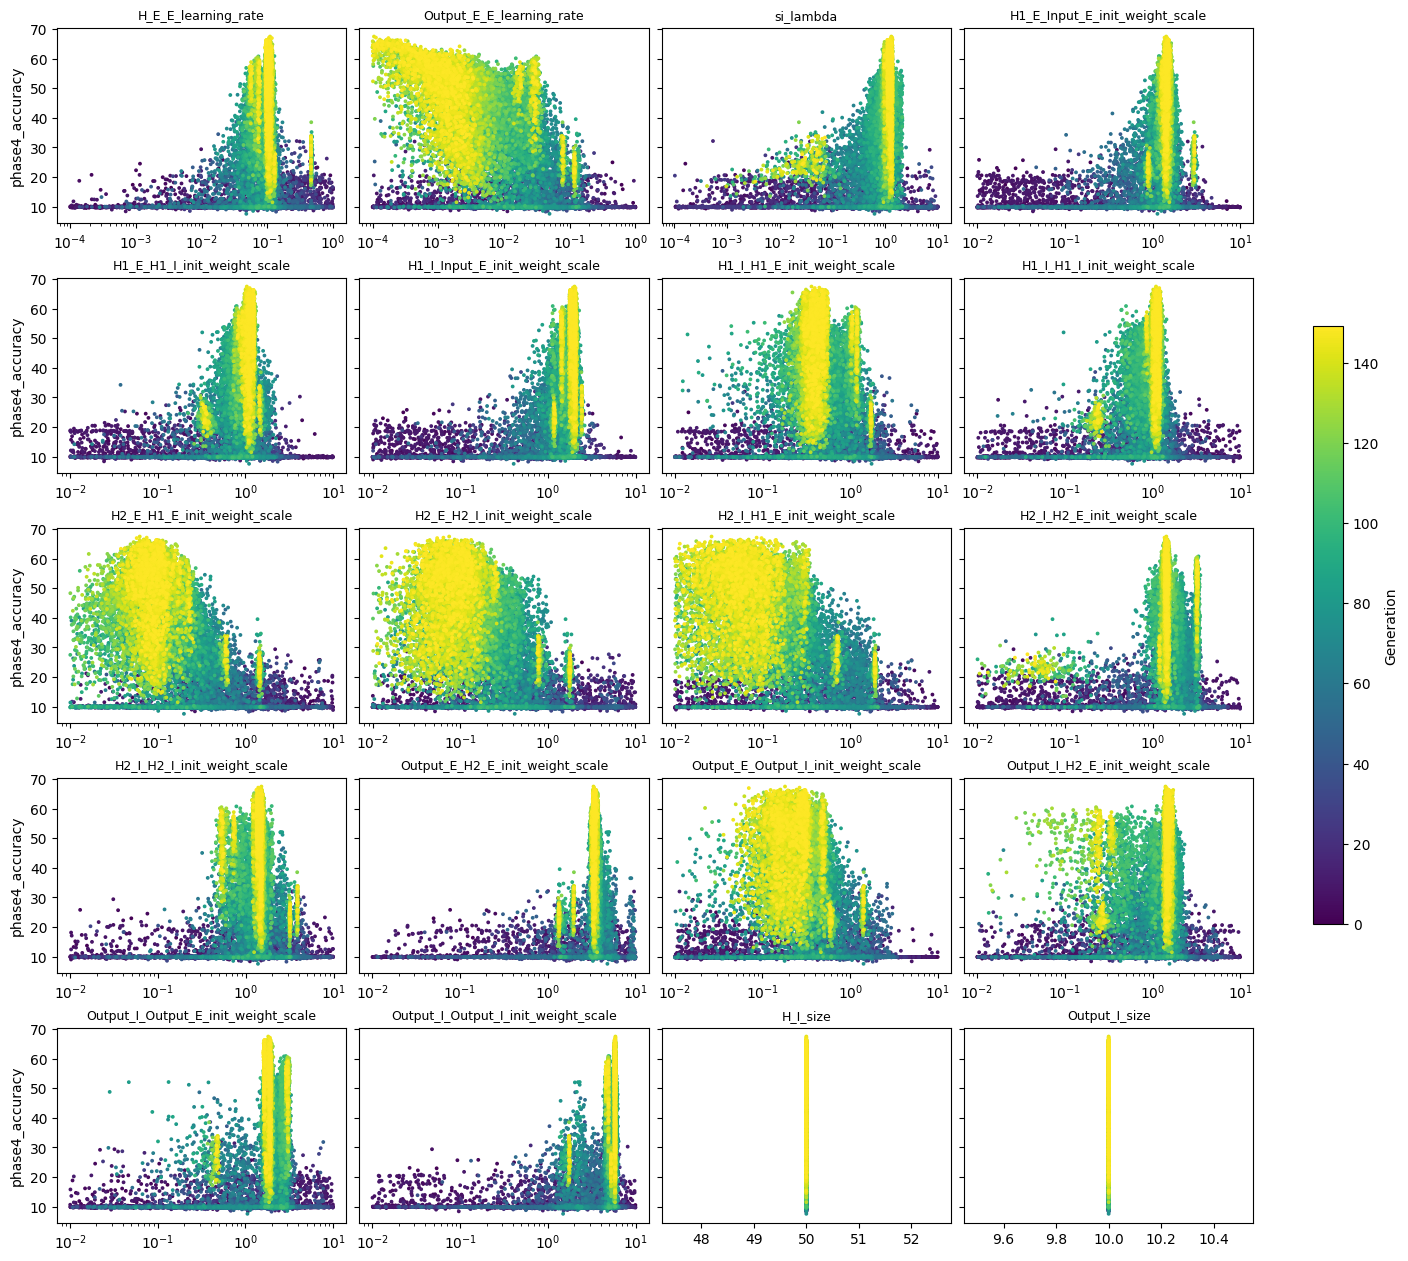

In [75]:
y_col = color_by

ncols = 4
nrows = int(np.ceil(len(param_names) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.5 * ncols, 2.5 * nrows), sharey=True, squeeze=False,
                         constrained_layout=True)
for ax, name in zip(axes.flat, param_names):
    sc = ax.scatter(df['param', name], df[y_col], c=df['meta', 'generation'], s=3, cmap='viridis', rasterized=True)
    if use_log_scale(bounds[name]):
        ax.set_xscale('log')
    ax.set_title(name, fontsize=9)
for ax in axes.flat[len(param_names):]:
    ax.axis('off')
for ax in axes[:, 0]:
    ax.set_ylabel(y_col[1])
fig.colorbar(sc, ax=axes, label='Generation', shrink=0.5)
plt.show()

## Failed models

Models whose evaluation failed. Nested stores only their params, so `failed_df` has `meta` and `param` columns but no
features or objectives.

In [76]:
failed_df[['meta', 'param']].drop(columns=[('meta', c) for c in ['survivor', 'energy', 'rank', 'fitness']])

meta                        param                           \
     generation model_id H_E_E_learning_rate Output_E_E_learning_rate   
0             0       23            0.208973                 0.002108   
1             0      106            0.005453                 0.000238   
2             0      191            0.024503                 0.431215   
3             1      397            0.265906                 0.612291   
4             2      458            0.019456                 0.048673   
...         ...      ...                 ...                      ...   
5702        149    29917            0.073525                 0.030560   
5703        149    29918            0.114997                 0.002479   
5704        149    29928            0.107851                 0.003014   
5705        149    29938            0.107320                 0.001346   
5706        149    29959            0.094038                 0.001609   

                                                                           \
     si_lambda H1_E_Input_E_init_weight_scale H1_E_H1_I_init_weight_scale   
0     0.435020                       0.524666                    1.416743   
1     2.472403                       4.565963                    0.756067   
2     1.805899                       1.855483                    0.625259   
3     0.726123                       0.690476                    0.382403   
4     0.839803                       2.428431                    0.334346   
...        ...                            ...                         ...   
5702  1.165652                       1.312931                    0.930656   
5703  1.284299                       1.451153                    1.144099   
5704  1.262986                       1.437734                    1.168048   
5705  1.304048                       1.447532                    0.986499   
5706  1.321640                       1.427571                    1.061553   

                                                                 \
     H1_I_Input_E_init_weight_scale H1_I_H1_E_init_weight_scale   
0                          0.014773                    1.692664   
1                          2.795331                    0.265895   
2                          9.268368                    7.254342   
3                          2.796249                    0.487519   
4                          0.527877                    0.431239   
...                             ...                         ...   
5702                       1.418780                    1.187193   
5703                       2.063243                    0.408362   
5704                       2.031463                    0.399663   
5705                       2.052151                    0.302628   
5706                       1.979062                    0.375288   

                                  ...                              \
     H1_I_H1_I_init_weight_scale  ... H2_I_H1_E_init_weight_scale   
0                       0.021621  ...                    0.561905   
1                       2.331186  ...                    1.953183   
2                       1.827116  ...                    1.069990   
3                       1.070979  ...                    0.299452   
4                       0.199864  ...                    0.013070   
...                          ...  ...                         ...   
5702                    1.028800  ...                    0.066740   
5703                    1.224057  ...                    0.109786   
5704                    1.155608  ...                    0.108818   
5705                    1.034312  ...                    0.087160   
5706                    1.086606  ...                    0.048089   

                                                              \
     H2_I_H2_E_init_weight_scale H2_I_H2_I_init_weight_scale   
0                       0.052473                    0.012965   
1                       0.169997                    0.126911   
2                       0.196594 

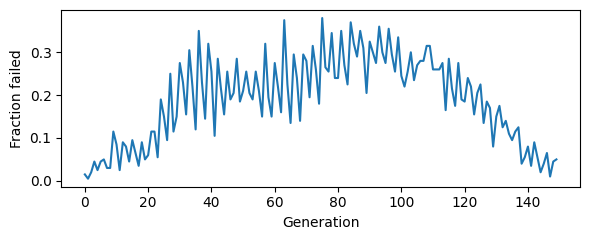

In [77]:
num_gens = len(history.generations)
failed_per_gen = failed_df['meta', 'generation'].value_counts().reindex(range(num_gens), fill_value=0)
evaluated_per_gen = df['meta', 'generation'].value_counts().reindex(range(num_gens), fill_value=0)

fig, ax = plt.subplots(figsize=(6, 2.5))
ax.plot(failed_per_gen / (failed_per_gen + evaluated_per_gen))
ax.set_xlabel('Generation')
ax.set_ylabel('Fraction failed')
fig.tight_layout()
plt.show()

Failure rate across each param's range: the fraction of models in each bin that failed (bins are log-spaced for
log-scale params). Gray bars are the number of models in each bin. A rising curve at one end of a param's range
points to the param that makes models fail.

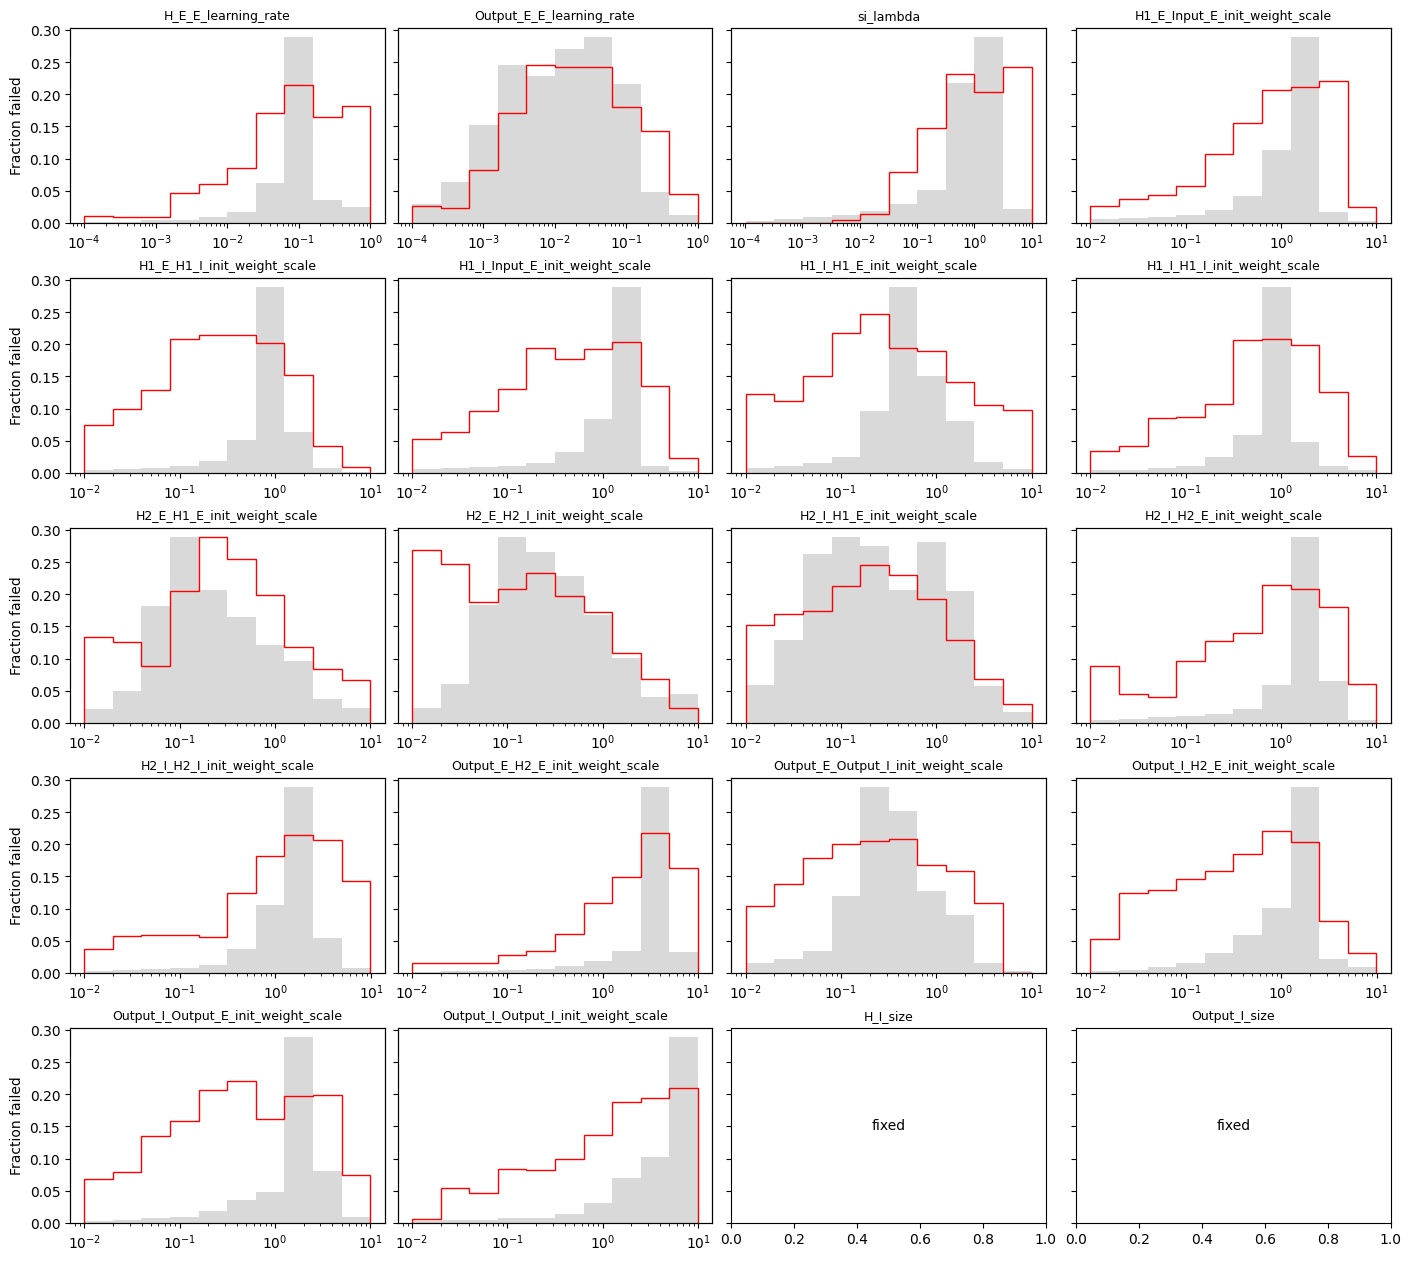

In [78]:
num_bins = 10

all_params = pd.concat([df['param'], failed_df['param']], ignore_index=True).astype(float)
is_failed = np.r_[np.zeros(len(df), bool), np.ones(len(failed_df), bool)]

ncols = 4
nrows = int(np.ceil(len(param_names) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.5 * ncols, 2.5 * nrows), sharey=True, squeeze=False,
                         constrained_layout=True)
for ax, name in zip(axes.flat, param_names):
    vals = all_params[name].values
    lo, hi = min(bounds[name][0], vals.min()), max(bounds[name][1], vals.max())
    ax.set_title(name, fontsize=9)
    if lo == hi:
        ax.text(0.5, 0.5, 'fixed', ha='center', va='center', transform=ax.transAxes)
        continue
    if use_log_scale((lo, hi)):
        edges = np.logspace(np.log10(lo), np.log10(hi), num_bins + 1)
        ax.set_xscale('log')
    else:
        edges = np.linspace(lo, hi, num_bins + 1)
    total, _ = np.histogram(vals, edges)
    failed, _ = np.histogram(vals[is_failed], edges)
    ax.stairs(np.divide(failed, total, out=np.full(num_bins, np.nan), where=total > 0), edges, color='r')
    count_ax = ax.twinx()
    count_ax.stairs(total, edges, fill=True, color='0.85', zorder=0)
    count_ax.set_yticks([])
    ax.set_zorder(count_ax.get_zorder() + 1)
    ax.patch.set_visible(False)
for ax in axes.flat[len(param_names):]:
    ax.axis('off')
for ax in axes[:, 0]:
    ax.set_ylabel('Fraction failed')
plt.show()